In [5]:
# PATCH EXTRACTION (±band, ≥30% OVERLAP) 
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import tifffile as tiff
import openslide
from shapely.geometry import shape, MultiPolygon
from shapely.affinity import affine_transform
from skimage.draw import polygon as sk_polygon
from scipy.ndimage import distance_transform_edt, gaussian_filter, binary_opening, binary_closing

# config
root = Path(r"C:\Users\Liyua\3945041\uw-loci\he_shg_synth_workflow-v0.1.0\uw-loci-he_shg_synth_workflow-fcf9bd5\PAADA9IH")
svs = "TCGA-3A-A9IH-01Z-00-DX1.578316D1-186E-4AE4-BD6A-DA426DE87829.svs"
geojson_path = root / "TCGA-3A-A9IH-01Z-00-DX1.578316D1-186E-4AE4-BD6A-DA426DE87829.geojson"
til5x_path   = root / "TCGA-3A-A9IH-01Z-00-DX1.png"
out_root     = Path(r"C:\Users\Liyua\Outputs\PAADA9IH_band_overlap")

patch_size_20x  = 2048                 # set 1024/2048 etc.
stride_20x      = patch_size_20x // 2  # denser -> //6 or //8 if needed
band_um         = 500.0               # symmetric band thickness (inside & outside)
min_overlap_frac = 0.30                # >=30% of tile area must overlap the band
til_sigma_um    = 50.0
mpp5_fallback   = 2.0                  # µm/px fallback if MPP is missing
shuffle_before_save = False            # set True to randomize order (no cap by default)

def ensure_dir(p): Path(p).mkdir(parents=True, exist_ok=True)

def read_geojson_geoms(path, allowed_classes=("Tumor","tumor","Tumour","tumour","Tumor core","TumorCore")):
    """Read polygons; try to filter by class; if no classes or no match => keep ALL."""
    with open(path, 'r', encoding='utf-8') as f:
        gj = json.load(f)
    feats = gj['features'] if 'features' in gj else [gj]
    geoms_all, geoms_keep, seen = [], [], set()
    for feat in feats:
        geom = feat.get("geometry")
        if not geom: continue
        shp = shape(geom)
        geoms_all.append(shp)
        props = feat.get("properties", {}) or {}
        cls = None
        if isinstance(props.get("classification"), dict):
            cls = props["classification"].get("name")
        cls = cls or props.get("name") or props.get("class") or props.get("type")
        if cls: seen.add(cls)
        if (allowed_classes is None) or (cls in allowed_classes):
            geoms_keep.append(shp)
    if allowed_classes is None:
        print(f"[GEOJSON] allowed_classes=None -> keeping ALL polygons ({len(geoms_all)}).")
        return geoms_all
    if geoms_keep:
        print(f"[GEOJSON] Using classes {allowed_classes}. Present: {sorted(seen)}. Kept {len(geoms_keep)} polygon(s).")
        return geoms_keep
    print(f"[GEOJSON] No matching classes (allowed={allowed_classes}, present={sorted(seen)}). "
          f"FALLBACK: keeping ALL ({len(geoms_all)}) polygons.")
    return geoms_all

def get_level_by_mag(slide, target_mag):
    props = slide.properties
    base_mag = None
    for k in ("aperio.AppMag", "openslide.objective-power"):
        if k in props:
            try: base_mag = float(props[k]); break
            except: pass
    if base_mag is None:
        downs = [slide.level_downsamples[i] for i in range(slide.level_count)]
        target_ratio = 20.0 / target_mag
        return int(np.argmin([abs(d - target_ratio) for d in downs]))
    downs = [slide.level_downsamples[i] for i in range(slide.level_count)]
    mags  = [base_mag / d for d in downs]
    return int(np.argmin([abs(m - target_mag) for m in mags]))

def get_mpp(slide, level):
    px, py = slide.properties.get("openslide.mpp-x"), slide.properties.get("openslide.mpp-y")
    if px and py:
        try:
            ds = float(slide.level_downsamples[level])
            return (float(px)+float(py))/2.0 * ds
        except: pass
    return None

def rasterize_polys_to_mask(polys_5x, w5, h5):
    mask = np.zeros((h5, w5), np.uint8)
    for p in polys_5x:
        parts = p.geoms if isinstance(p, MultiPolygon) else [p]
        for g in parts:
            ex = np.asarray(g.exterior.coords, dtype=np.float32)
            rr, cc = sk_polygon(ex[:,1], ex[:,0], mask.shape)
            mask[rr, cc] = 1
            for hole in g.interiors:
                h = np.asarray(hole.coords, dtype=np.float32)
                r, c = sk_polygon(h[:,1], h[:,0], mask.shape)
                mask[r, c] = 0
    if mask.any():
        mask = binary_opening(mask, np.ones((3,3)))
        mask = binary_closing(mask, np.ones((5,5)))
    return mask

def quick_tissue_mask_5x(rgb5):
    hsv = cv2.cvtColor(rgb5, cv2.COLOR_RGB2HSV)
    s, v = hsv[...,1], hsv[...,2]
    g = cv2.cvtColor(rgb5, cv2.COLOR_RGB2GRAY)
    _, thr = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    mask = ((s>15) & (v<252) & (g<thr)).astype(np.uint8)
    mask = binary_opening(mask, np.ones((3,3)))
    mask = binary_closing(mask, np.ones((7,7)))
    return mask

def iou(a,b):
    inter = np.logical_and(a>0,b>0).sum()
    uni   = np.logical_or(a>0,b>0).sum()
    return inter/uni if uni>0 else 0.

def detect_geojson_to_5x(slide, l5, geoms0):
    """Auto-detect whether GeoJSON is level-0 px / microns / already 5×; return polygons in 5× pixels."""
    ds5 = float(slide.level_downsamples[l5])
    w5, h5 = slide.level_dimensions[l5]
    rgb5 = np.array(slide.read_region((0,0), l5, (w5,h5)))[:,:,:3]
    tissue5 = quick_tissue_mask_5x(rgb5)
    px,py = slide.properties.get("openslide.mpp-x"), slide.properties.get("openslide.mpp-y")
    mpp0 = (float(px)+float(py))/2.0 if (px and py) else None

    hyps=[]
    # H1: level-0 px -> /ds5
    polys_h1 = [affine_transform(p,(1/ds5,0,0,1/ds5,0,0)) for p in geoms0]
    hyps.append(("level0_pixels", polys_h1, iou(rasterize_polys_to_mask(polys_h1, w5, h5), tissue5)))
    # H2: microns -> /(mpp0*ds5)
    if mpp0:
        sx = sy = 1.0/(mpp0*ds5)
        polys_h2 = [affine_transform(p,(sx,0,0,sy,0,0)) for p in geoms0]
        hyps.append(("microns", polys_h2, iou(rasterize_polys_to_mask(polys_h2, w5, h5), tissue5)))
    # H3: already 5× px
    polys_h3 = geoms0
    hyps.append(("already_5x_pixels", polys_h3, iou(rasterize_polys_to_mask(polys_h3, w5, h5), tissue5)))

    mode, polys5, best_iou = max(hyps, key=lambda t: t[2])
    print(f"[ALIGN] GeoJSON best hypothesis: {mode} (IoU={best_iou:.3f})")
    return polys5

def signed_distance_um(core_mask, mpp_um):
    d_in  = distance_transform_edt(core_mask)
    d_out = distance_transform_edt(1-core_mask)
    return ((d_out - d_in) * float(mpp_um)).astype(np.float32)  # <0 intra, >0 peri

def til_binary_from_red(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    m = cv2.inRange(hsv, (0,80,80),(10,255,255)) | cv2.inRange(hsv,(170,80,80),(180,255,255))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3,3),np.uint8))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5,5),np.uint8))
    return (m>0).astype(np.uint8)

def density_from_binary(mask, sigma_um, mpp_um):
    s = max(1.0, float(sigma_um)/float(mpp_um))
    den = gaussian_filter(mask.astype(np.float32), s)
    return (den/den.max() if den.max()>0 else den).astype(np.float32)

# ---- OVERLAP-BASED SELECTION (±band) ----
def select_band_overlap(slide, level20, ps, stride,
                        band5_mask, ds5, ds20,
                        min_overlap_frac=0.30,
                        shuffle=True, seed=42):
    """
    Keep a tile if its 5× footprint overlaps the ±band by >= min_overlap_frac of the
    *in-bounds* tile area. Collect ALL candidates, then optionally shuffle (no cap).
    """
    w20, h20 = slide.level_dimensions[level20]
    # tile size & mapping
    w5p = int(ps * ds20 / ds5)
    h5p = w5p
    to5 = ds20 / ds5

    # integral image with padding for O(1) rectangle sums
    band = (band5_mask > 0).astype(np.uint8)
    ii = np.pad(band, ((1,0),(1,0)), mode='constant', constant_values=0).cumsum(0).cumsum(1)
    def rect_sum(x, y, w, h):
        x0 = max(0, x); y0 = max(0, y)
        x1 = min(band.shape[1], x + w); y1 = min(band.shape[0], y + h)
        if x1 <= x0 or y1 <= y0:
            return 0, 0
        # convert to integral indices (+1 due to padding)
        x0i, y0i, x1i, y1i = x0+1, y0+1, x1+1, y1+1
        s = ii[y1i, x1i] - ii[y0i, x1i] - ii[y1i, x0i] + ii[y0i, x0i]
        return int(s), int((x1 - x0) * (y1 - y0))

    candidates = []
    total = 0
    for y in range(0, h20 - ps + 1, stride):
        for x in range(0, w20 - ps + 1, stride):
            total += 1
            x5 = int(x * to5); y5 = int(y * to5)
            s, ain = rect_sum(x5, y5, w5p, h5p)
            if ain == 0: 
                continue
            if (s / ain) >= float(min_overlap_frac):
                candidates.append({"x20": x, "y20": y})

    print(f"[SELECT] windows checked: {total}")
    print(f"[SELECT] overlap hits (≥{min_overlap_frac:.2f}): {len(candidates)}")

    if shuffle and len(candidates) > 1:
        rng = np.random.default_rng(seed)
        rng.shuffle(candidates)

    print(f"[SELECT] final selected: {len(candidates)} (stride={stride}, ps={ps})")
    return candidates

def extract_one(slide, lvl20, sel, ps, ds20, ds5, til_den5, til_bin5, dist5_um, band5_mask):
    x, y = sel["x20"], sel["y20"]
    x0, y0 = int(x*ds20), int(y*ds20)
    he = np.array(slide.read_region((x0,y0), lvl20, (ps,ps)))[:,:,:3]

    x5, y5 = int(x*ds20/ds5), int(y*ds20/ds5)
    w5p = int(ps*ds20/ds5)

    tb = cv2.resize(til_bin5[y5:y5+w5p, x5:x5+w5p], (ps,ps), cv2.INTER_NEAREST)
    td = cv2.resize(til_den5[y5:y5+w5p, x5:x5+w5p], (ps,ps), cv2.INTER_LINEAR)
    di = cv2.resize(dist5_um[y5:y5+w5p, x5:x5+w5p], (ps,ps), cv2.INTER_LINEAR)
    bg = cv2.resize(band5_mask[y5:y5+w5p, x5:x5+w5p], (ps,ps), cv2.INTER_NEAREST)

    tb = (tb>0.5).astype(np.uint8)
    intra = (di<0).astype(np.uint8); peri = (di>=0).astype(np.uint8)
    t_in, t_pe = tb*intra, tb*peri

    lab = dict(
        has_tcells_bin=int(tb.sum()>0),
        has_tcells_intra=int(t_in.sum()>0),
        has_tcells_peri=int(t_pe.sum()>0),
        til_area_px=int(tb.sum()),
        til_area_intra_px=int(t_in.sum()),
        til_area_peri_px=int(t_pe.sum()),
        til_den_sum=float(td.sum()),
        til_den_mean=float(td.mean()),
        til_den_intra_mean=float((td*intra).sum()/max(1,intra.sum())),
        til_den_peri_mean=float((td*peri).sum()/max(1,peri.sum())),
        band_frac=float(bg.mean())
    )
    return he, tb, td, di, bg, t_in, t_pe, lab

# MAIN 
slide = openslide.OpenSlide(str(root/svs))
l5  = get_level_by_mag(slide, 5)
l20 = get_level_by_mag(slide, 20)
ds5, ds20 = float(slide.level_downsamples[l5]), float(slide.level_downsamples[l20])
mpp5 = get_mpp(slide, l5) or mpp5_fallback
w5, h5 = slide.level_dimensions[l5]
print(f"[INFO] L{l20}@20×  L{l5}@5×   mpp5={mpp5:.2f} µm/px")

# GeoJSON → 5× pixels (auto) & core 
geoms0 = read_geojson_geoms(str(geojson_path), allowed_classes=None)  # or pass your tumor class list
polys5 = detect_geojson_to_5x(slide, l5, geoms0)
core5  = rasterize_polys_to_mask(polys5, w5, h5)  # 1 = tumor

# Signed distance @5× (µm) + ±band mask 
dist5_um = signed_distance_um(core5, mpp5)                 # <0 intra, >0 peri
band5    = (np.abs(dist5_um) <= band_um).astype(np.uint8)  # inside+outside

# TIL @5× 
til5 = cv2.cvtColor(cv2.imread(str(til5x_path)), cv2.COLOR_BGR2RGB)
if til5 is None: raise FileNotFoundError(f"TIL map not found: {til5x_path}")
if (til5.shape[1], til5.shape[0]) != (w5, h5):
    til5 = cv2.resize(til5, (w5, h5), cv2.INTER_NEAREST)
    warnings.warn("Resized TIL map to 5× frame.")
til_bin5 = til_binary_from_red(til5)
til_den5 = density_from_binary(til_bin5, til_sigma_um, mpp5)

# SELECT by ≥30% overlap with ±band (no cap)
sels = select_band_overlap(
    slide, l20, patch_size_20x, stride_20x,
    band5, ds5, ds20,
    min_overlap_frac=min_overlap_frac,
    shuffle=shuffle_before_save, seed=42
)

# OUTPUT DIRS 
he_dir   = out_root/"patches_20x/HE"
til_dir  = out_root/"patches_20x/TIL"
dist_dir = out_root/"patches_20x/DIST"
ring_dir = out_root/"patches_20x/RINGS"
meta_dir = out_root/"patches_20x/META"
for d in (he_dir, til_dir, dist_dir, ring_dir, meta_dir): ensure_dir(d)

#EXTRACT & SAVE
rows=[]; kept=0
for s in sels:
    he, tb, td, di, bg, t_in, t_pe, lab = extract_one(slide, l20, s, patch_size_20x, ds20, ds5,
                                                      til_den5, til_bin5, dist5_um, band5)
    pid=f"patch_{kept:04d}"
    cv2.imwrite(str(he_dir/f"{pid}.png"), cv2.cvtColor(he, cv2.COLOR_RGB2BGR))
    tiff.imwrite(str(til_dir/f"{pid}_til_bin.tif"), tb)
    tiff.imwrite(str(til_dir/f"{pid}_til_den.tif"), td)
    tiff.imwrite(str(til_dir/f"{pid}_til_intra_bin.tif"), t_in)
    tiff.imwrite(str(til_dir/f"{pid}_til_peri_bin.tif"), t_pe)
    tiff.imwrite(str(dist_dir/f"{pid}_dist_um.tif"), di)
    tiff.imwrite(str(ring_dir/f"{pid}_band_pm_{int(band_um)}um.tif"), bg)

    rows.append(dict(
        patch_id=pid, x20=int(s["x20"]), y20=int(s["y20"]),
        band_frac=float(lab["band_frac"]),
        til_area_px=lab["til_area_px"], til_area_intra_px=lab["til_area_intra_px"], til_area_peri_px=lab["til_area_peri_px"],
        til_den_sum=lab["til_den_sum"], til_den_mean=lab["til_den_mean"],
        til_den_intra_mean=lab["til_den_intra_mean"], til_den_peri_mean=lab["til_den_peri_mean"],
        has_tcells_bin=lab["has_tcells_bin"], has_tcells_intra=lab["has_tcells_intra"], has_tcells_peri=lab["has_tcells_peri"]
    ))
    kept += 1

pd.DataFrame(rows).to_csv(meta_dir/"manifest.csv", index=False)
print(f"[DONE] Saved {kept} patches → {meta_dir/'manifest.csv'}")


[INFO] L1@20×  L2@5×   mpp5=4.04 µm/px
[GEOJSON] allowed_classes=None -> keeping ALL polygons (4).
[ALIGN] GeoJSON best hypothesis: level0_pixels (IoU=0.000)


C:\Users\Liyua\AppData\Local\Temp\ipykernel_31168\2396268492.py:266: UserWarning: Resized TIL map to 5× frame.
  warnings.warn("Resized TIL map to 5× frame.")
C:\Users\Liyua\AppData\Local\Temp\ipykernel_31168\2396268492.py:186: RuntimeWarning: overflow encountered in scalar subtract
  s = ii[y1i, x1i] - ii[y0i, x1i] - ii[y1i, x0i] + ii[y0i, x0i]
C:\Users\Liyua\AppData\Local\Temp\ipykernel_31168\2396268492.py:186: RuntimeWarning: overflow encountered in scalar add
  s = ii[y1i, x1i] - ii[y0i, x1i] - ii[y1i, x0i] + ii[y0i, x0i]


[SELECT] windows checked: 300
[SELECT] overlap hits (≥0.30): 4
[SELECT] final selected: 4 (stride=1024, ps=2048)
[DONE] Saved 4 patches → C:\Users\Liyua\Outputs\PAADA9IH_band_overlap\patches_20x\META\manifest.csv


[INFO] manifest patches: 12
[ALIGN] overview using: level0_pixels (IoU=0.000)


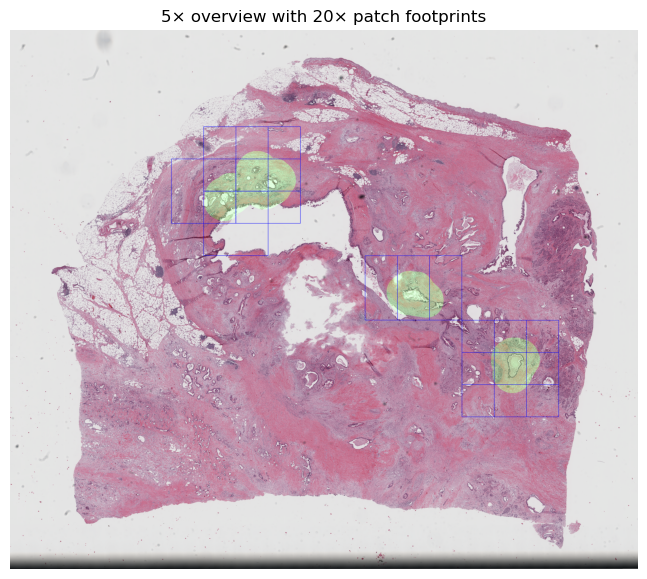

In [3]:
# 5× OVERVIEW with PATCH FOOTPRINTS (uses the same detector) 
import json, numpy as np, cv2, tifffile as tiff, matplotlib.pyplot as plt, pandas as pd
from pathlib import Path
import openslide
from shapely.geometry import shape
from shapely.affinity import affine_transform
from skimage.draw import polygon as sk_polygon
from scipy.ndimage import binary_opening, binary_closing

root = Path(r"C:\Users\Liyua\3945041\uw-loci\he_shg_synth_workflow-v0.1.0\uw-loci-he_shg_synth_workflow-fcf9bd5\PAADAABK")
svs  = "TCGA-2J-AABK-01Z-00-DX1.AF5DE1FD-40EE-4149-8918-B53EC2DF727E.svs"
geojson_path = root / "TCGA-2J-AABK-01Z-00-DX1.AF5DE1FD-40EE-4149-8918-B53EC2DF727E.geojson"
out_root = Path(r"C:\Users\Liyua\Outputs\PAADAABK_band_overlap")
meta_dir = out_root / "patches_20x" / "META"
he_dir   = out_root / "patches_20x" / "HE"
til_dir  = out_root / "patches_20x" / "TIL"

band_um = 500.0   # for band overlay (should match extraction)

def read_geojson_geoms(path):
    with open(path,'r',encoding='utf-8') as f: gj=json.load(f)
    feats = gj['features'] if 'features' in gj else [gj]
    return [shape(feat['geometry']) for feat in feats if feat.get('geometry')]

def rasterize_polys_to_mask(polys_5x, w5, h5):
    mask = np.zeros((h5,w5), np.uint8)
    for p in polys_5x:
        parts = p.geoms if hasattr(p,'geoms') else [p]
        for g in parts:
            ex = np.asarray(g.exterior.coords, dtype=np.float32)
            rr, cc = sk_polygon(ex[:,1], ex[:,0], mask.shape)
            mask[rr, cc] = 1
            for hole in g.interiors:
                h = np.asarray(hole.coords, dtype=np.float32)
                r, c = sk_polygon(h[:,1], h[:,0], mask.shape)
                mask[r, c] = 0
    return mask

def signed_distance_um(core_mask, mpp_um):
    from scipy.ndimage import distance_transform_edt
    d_in  = distance_transform_edt(core_mask)
    d_out = distance_transform_edt(1-core_mask)
    return ((d_out - d_in) * float(mpp_um)).astype(np.float32)

def quick_tissue_mask_5x(rgb5):
    hsv = cv2.cvtColor(rgb5, cv2.COLOR_RGB2HSV)
    s, v = hsv[...,1], hsv[...,2]
    g = cv2.cvtColor(rgb5, cv2.COLOR_RGB2GRAY)
    _, thr = cv2.threshold(g,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    mask = ((s>15) & (v<252) & (g<thr)).astype(np.uint8)
    return binary_closing(binary_opening(mask, np.ones((3,3))), np.ones((7,7)))

def iou(a,b):
    inter = np.logical_and(a>0,b>0).sum()
    uni   = np.logical_or(a>0,b>0).sum()
    return inter/uni if uni>0 else 0.

def detect_geojson_to_5x(slide, l5, geoms0):
    ds5 = float(slide.level_downsamples[l5])
    w5,h5 = slide.level_dimensions[l5]
    rgb5 = np.array(slide.read_region((0,0), l5, (w5,h5)))[:,:,:3]
    tissue5 = quick_tissue_mask_5x(rgb5)
    px,py = slide.properties.get("openslide.mpp-x"), slide.properties.get("openslide.mpp-y")
    mpp0 = (float(px)+float(py))/2.0 if (px and py) else None

    hyps=[]
    polys_h1 = [affine_transform(p,(1/ds5,0,0,1/ds5,0,0)) for p in geoms0]
    hyps.append(("level0_pixels", polys_h1, iou(rasterize_polys_to_mask(polys_h1,w5,h5), tissue5)))
    if mpp0:
        sx=sy=1.0/(mpp0*ds5)
        polys_h2 = [affine_transform(p,(sx,0,0,sy,0,0)) for p in geoms0]
        hyps.append(("microns", polys_h2, iou(rasterize_polys_to_mask(polys_h2,w5,h5), tissue5)))
    polys_h3 = geoms0
    hyps.append(("already_5x_pixels", polys_h3, iou(rasterize_polys_to_mask(polys_h3,w5,h5), tissue5)))
    best=max(hyps,key=lambda t:t[2])
    print(f"[ALIGN] overview using: {best[0]} (IoU={best[2]:.3f})")
    return best[1]

slide = openslide.OpenSlide(str(root/svs))
l5 = (lambda s: (lambda downs: int(np.argmin([abs((float(slide.properties.get('aperio.AppMag', slide.properties.get('openslide.objective-power', 20))) / d) - 5) for d in downs]))))(slide)([slide.level_downsamples[i] for i in range(slide.level_count)])
ds5 = float(slide.level_downsamples[l5])
w5,h5 = slide.level_dimensions[l5]
bg5 = np.array(slide.read_region((0,0), l5, (w5,h5)))[:,:,:3]

px,py = slide.properties.get("openslide.mpp-x"), slide.properties.get("openslide.mpp-y")
mpp5 = ((float(px)+float(py))/2.0)*ds5 if (px and py) else 2.0

man = pd.read_csv(meta_dir/"manifest.csv")
print(f"[INFO] manifest patches: {len(man)}")

geoms0 = read_geojson_geoms(str(geojson_path))
polys5 = detect_geojson_to_5x(slide, l5, geoms0)
core5  = rasterize_polys_to_mask(polys5, w5, h5)
sdist5 = signed_distance_um(core5, mpp5)
band5  = (np.abs(sdist5) <= band_um).astype(np.uint8)

overlay = (bg5 * 0.95).astype(np.uint8)
band_rgb = np.zeros_like(overlay); band_rgb[...,1] = band5*200
overlay = cv2.addWeighted(overlay, 1.0, band_rgb, 0.35, 0)

l20 = (lambda s: (lambda downs: int(np.argmin([abs((float(slide.properties.get('aperio.AppMag', slide.properties.get('openslide.objective-power', 20))) / d) - 20) for d in downs]))))(slide)([slide.level_downsamples[i] for i in range(slide.level_count)])
ds20 = float(slide.level_downsamples[l20])
example_til = til_dir / f"{man['patch_id'].iloc[0]}_til_bin.tif"
ps = tiff.imread(str(example_til)).shape[0]
w5p = int(ps*ds20/ds5); h5p = w5p

for i, r in man.iterrows():
    x20,y20 = int(r["x20"]), int(r["y20"])
    x0,y0   = int(x20*ds20), int(y20*ds20)
    x5,y5   = int(x0/ds5),   int(y0/ds5)
    cv2.rectangle(overlay, (x5,y5), (x5+w5p, y5+h5p), (0,0,255), 2)

plt.figure(figsize=(10,7))
plt.imshow(overlay); plt.axis('off'); plt.title("5× overview with 20× patch footprints")
plt.show()
